# 01. Group-contribution baselines (JRGC)

**Purpose.** Measure how well the group-contribution (GC) estimate predicts the
experimental values, and score it exactly the way the GC-GP models of notebook 04
are scored, so that the two can be compared molecule by molecule.

**Two matched baselines (Sections 2 to 6).** Both use the curated datasets of
`00_Data_Curation.ipynb` (the same molecules, in the same order, as notebook 04) and
the same ten folds (scikit-learn `KFold`, shuffled, seed 42):

* **Raw GC estimate.** The Joback-Reid value (Wildman-Crippen for log P) with no
  fitting. Every molecule is scored once, in the fold in which notebook 04 holds it
  out, so pooled and per-fold metrics are directly comparable with the GC-GP test
  metrics.
* **Linear recalibration.** `y = a·MW + b·y_GC + c`, fitted by least squares on the
  nine training folds and used to predict the held-out fold. It has the same two
  inputs as the GP, and it equals the mean function of GC-GP Method 4 without the
  kernel, so the difference between it and GC-GP is the contribution of the kernel.

**Main-text Table 2 (Section 7)** puts the raw GC estimate, the linear recalibration
and GC-GP side by side. It needs the out-of-fold predictions of notebook 04; if they
are not there yet, the section says so and is skipped. Run notebook 04, then run this
notebook again.

**Legacy baseline (Section 9).** The earlier fitted baseline (one 80/20 split of the
uncurated input files; for Tb and Tm with four topological indices) is kept unchanged
for SI Table S4 and Fig. S3. Notebooks 04 and 07 still read its files, so its output
paths are unchanged.

**What this notebook writes** (in `Output_Data/jrgc_baseline/`)

* `matched_cv/<run>/`: out-of-fold predictions, per-fold metrics and parity plots of
  both matched baselines, and the fitted coefficients of the linear recalibration.
* `matched_cv/matched_baseline_summary.csv`: pooled and per-fold metrics, with the same
  column names as `final_gcgp_cv/final_cv_summary.csv`.
* `matched_cv/fig2_rawGC_parity_grid.png/.pdf`: the raw GC parity plots of all
  properties (main-text Fig. 2).
* `matched_cv/table2_matched_comparison.csv`: main-text Table 2.
* The legacy files (`JRGC_statistical_metrics.csv` and others) as before.

## 1. Environment and setup

Imports, the global random seed and the output folders. All paths are relative to the
repository. Only shared functions that already exist are imported; the matched-baseline
code is written out in this notebook.

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

from gcgp.settings import (GLOBAL_SEED, OUTPUT_DIR, checkCuratedData, checkInputs, describeSetup,
                           getRunSettings, isFastRun, outputFolder, setGlobalSeed)
from gcgp.properties import PROPERTIES, PROPERTY_ORDER, loadPropertyData
from gcgp.metrics import calculateMetrics, countOutside95
from gcgp.plotting import TEST_COLOR, addMetricsText, finishFigure, plotParity, savePlot
from gcgp.narrative import showAndSave
from gcgp.jrgcBaseline import BASELINE_FEATURES, loadDescriptorTable, prepareBaselineData, runBaseline

setGlobalSeed()
outputDir = outputFolder("jrgc_baseline")
matchedDir = outputFolder("jrgc_baseline", "matched_cv")
gcgpDir = OUTPUT_DIR / "final_gcgp_cv"
pd.set_option("display.precision", 3)
checkInputs(("model_building", "raw"))
checkCuratedData()

# Run names used for the result folders; the same names as gcgp.finalConfig.RUN_NAMES,
# repeated here so that this notebook does not need the GP libraries.
RUN_NAMES = {"Tb": "Tb", "Tm": "Tm", "Pc": "Pc", "Vc": "Vc", "Tc": "Tc", "Hvap": "Hvap", "logP": "LogP"}

# Same fold count as notebook 04 (runGpCrossValidation): 10, unless a fast run overrides it.
N_FOLDS = int(getRunSettings()["nFolds"] or 10)
BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 0
showPlots = True
print(describeSetup())
print(f"Folds         : {N_FOLDS} (KFold, shuffled, seed {GLOBAL_SEED})")

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42
Folds         : 10 (KFold, shuffled, seed 42)


## 2. Data

Each property is read with `loadPropertyData`, the loader notebook 04 uses, so rows,
row order and row indices are identical. The inputs are the two GP inputs: molecular
weight and the GC estimate.

In [2]:
propertyData = {code: loadPropertyData(code) for code in PROPERTY_ORDER}

pd.DataFrame([
    {"Property": code,
     "Molecules": len(propertyData[code]),
     "Inputs": ", ".join(PROPERTIES[code]["featureCols"]),
     "Target": PROPERTIES[code]["targetCol"]}
    for code in PROPERTY_ORDER
])

,Property,Molecules,Inputs,Target
0,Tb,886,"Mol. wt., JR Tb /K",CRC Tb /K
1,Tm,1839,"Mol. wt., JR Tm /K",CRC Tm /K
2,Pc,75,"Mol. wt., JR Pc /Bars",CRC Pc /Bars
3,Vc,69,"Mol. wt., JR Vc /(cm3 mol-1)",CRC Vc /(cm3 mol-1)
4,Tc,70,"Mol. wt., JR Tc /K",CRC Tc /K
5,Hvap,70,"Mol. Wt., JR Hvap /(kJ mol-1)",CRC Hvap /(kJ mol-1)
6,logP,2978,"Mol. wt., Log P (JR)",logP (CRC)


## 3. Baseline functions

* `makeFolds` reproduces the fold assignment of `runGpCrossValidation` (notebook 04):
  `KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)` on the rows of the curated
  dataset. The split depends only on the number of rows and the seed.
* `runRawGc` scores the GC column. Each molecule appears once, labelled with the fold
  in which notebook 04 holds it out. There is no training set and no interval.
* `runLinearRecalibration` fits `y = a·MW + b·y_GC + c` in every fold and predicts the
  nine training folds (in-fold) and the held-out fold (out-of-fold), exactly like the
  GP. Its 95% interval is the ordinary least-squares prediction interval for a new
  measurement, `t(0.975, n−3) · s · sqrt(1 + x0ᵀ(XᵀX)⁻¹x0)`, which, like the GP
  interval, includes the noise term.
* Prediction tables have the same columns as the files of notebook 04
  (experimental, predicted, `95% CI`, `Fold`, `Set`, `RowIndex`, `SMILES`), and all
  metrics come from `calculateMetrics`, the function notebook 04 uses.

In [3]:
def makeFolds(nRows, nFolds=N_FOLDS, seed=GLOBAL_SEED):
    # List of (foldIndex, trainIdx, testIdx), identical to the folds of notebook 04.
    splitter = KFold(n_splits=nFolds, shuffle=True, random_state=seed)
    return [(k, trainIdx, testIdx)
            for k, (trainIdx, testIdx) in enumerate(splitter.split(np.zeros((nRows, 1))), start=1)]


def foldMetricRow(foldIndex, yTrainTrue, yTrainPred, yTestTrue, yTestPred, ciTrain=None, ciTest=None):
    testStats = calculateMetrics(yTestTrue, yTestPred)
    row = {"Fold": foldIndex, "N_Test": len(yTestTrue)}
    if yTrainTrue is not None:
        trainStats = calculateMetrics(yTrainTrue, yTrainPred)
        row["N_Train"] = len(yTrainTrue)
        row.update({f"Train_{m}": trainStats[m] for m in ["R2", "MAE", "RMSE", "MAPE"]})
    row.update({f"Test_{m}": testStats[m] for m in ["R2", "MAE", "RMSE", "MAPE"]})
    if ciTest is not None:
        row["CI_Train_Outside_Frac"] = countOutside95(yTrainTrue, yTrainPred, ciTrain)[1]
        row["CI_Test_Outside_Frac"] = countOutside95(yTestTrue, yTestPred, ciTest)[1]
    return row


def summaryRow(runName, modelName, nMolecules, foldDf, trainOverall, testOverall,
               outTrain=np.nan, outTest=np.nan):
    # Same column names as final_gcgp_cv/final_cv_summary.csv (notebook 04).
    trainR2 = trainOverall["R2"] if trainOverall is not None else np.nan
    return {
        "Property": runName, "Model": modelName, "N_Molecules": nMolecules,
        "N_Folds": len(foldDf), "Overall_Train_R2": trainR2, "Overall_Test_R2": testOverall["R2"],
        "Overfitting_Delta_R2": trainR2 - testOverall["R2"],
        "Overall_Test_MAE": testOverall["MAE"], "Overall_Test_RMSE": testOverall["RMSE"],
        "Overall_Test_MAPE": testOverall["MAPE"], "Overall_Test_MPE": testOverall["MPE"],
        "Mean_Test_R2": foldDf["Test_R2"].mean(), "Std_Test_R2": foldDf["Test_R2"].std(),
        "Mean_Test_MAE": foldDf["Test_MAE"].mean(), "Std_Test_MAE": foldDf["Test_MAE"].std(),
        "Mean_Test_RMSE": foldDf["Test_RMSE"].mean(), "Std_Test_RMSE": foldDf["Test_RMSE"].std(),
        "CI_Train_Outside_Frac": outTrain, "CI_Test_Outside_Frac": outTest,
    }


def runRawGc(code, data):
    info = PROPERTIES[code]
    xLabel, yLabel = info["xLabel"], info["yLabel"]
    y = data[info["targetCol"]].to_numpy(dtype=float)
    gc = data[info["featureCols"][1]].to_numpy(dtype=float)
    smiles = data["PubChem SMILES"].to_numpy()
    parts, foldRows = [], []
    for k, _, testIdx in makeFolds(len(data)):
        parts.append(pd.DataFrame({xLabel: y[testIdx], yLabel: gc[testIdx], "95% CI": np.nan,
                                   "Fold": k, "Set": "Test", "RowIndex": testIdx, "SMILES": smiles[testIdx]}))
        foldRows.append(foldMetricRow(k, None, None, y[testIdx], gc[testIdx]))
    predictions = pd.concat(parts, ignore_index=True)
    foldDf = pd.DataFrame(foldRows)
    testOverall = calculateMetrics(predictions[xLabel], predictions[yLabel])
    summary = summaryRow(RUN_NAMES[code], "Raw GC estimate", len(data), foldDf, None, testOverall)
    return {"predictions": predictions, "folds": foldDf, "summary": summary}


def olsPredictionHalfWidth(XTrain, residuals, XNew, level=0.95):
    # Half-width of the OLS prediction interval for a new measurement at XNew.
    design = np.column_stack([np.ones(len(XTrain)), XTrain])
    newDesign = np.column_stack([np.ones(len(XNew)), XNew])
    dof = len(XTrain) - design.shape[1]
    s = np.sqrt(np.sum(residuals ** 2) / dof)
    leverage = np.einsum("ij,jk,ik->i", newDesign, np.linalg.pinv(design.T @ design), newDesign)
    return stats.t.ppf(0.5 + level / 2, dof) * s * np.sqrt(1 + leverage)


def runLinearRecalibration(code, data):
    info = PROPERTIES[code]
    xLabel, yLabel = info["xLabel"], info["yLabel"]
    X = data[info["featureCols"]].to_numpy(dtype=float)
    y = data[info["targetCol"]].to_numpy(dtype=float)
    smiles = data["PubChem SMILES"].to_numpy()
    parts, foldRows, coefRows = [], [], []
    for k, trainIdx, testIdx in makeFolds(len(data)):
        model = LinearRegression().fit(X[trainIdx], y[trainIdx])
        predTrain, predTest = model.predict(X[trainIdx]), model.predict(X[testIdx])
        residuals = y[trainIdx] - predTrain
        ciTrain = olsPredictionHalfWidth(X[trainIdx], residuals, X[trainIdx])
        ciTest = olsPredictionHalfWidth(X[trainIdx], residuals, X[testIdx])
        for setName, idx, pred, ci in [("Train", trainIdx, predTrain, ciTrain), ("Test", testIdx, predTest, ciTest)]:
            parts.append(pd.DataFrame({xLabel: y[idx], yLabel: pred, "95% CI": ci, "Fold": k, "Set": setName,
                                       "RowIndex": idx, "SMILES": smiles[idx]}))
        foldRows.append(foldMetricRow(k, y[trainIdx], predTrain, y[testIdx], predTest, ciTrain, ciTest))
        # Coefficients on inputs and target standardised with the training fold, the
        # scale of the GC-GP Method 4 mean function (SI Table S2).
        xMean, xStd = X[trainIdx].mean(axis=0), X[trainIdx].std(axis=0)
        yMean, yStd = y[trainIdx].mean(), y[trainIdx].std()
        coefRows.append({"Fold": k, "a_MW_property_units": model.coef_[0], "b_GC_property_units": model.coef_[1],
                         "c_intercept": model.intercept_,
                         "a_MW_standardised": model.coef_[0] * xStd[0] / yStd,
                         "b_GC_standardised": model.coef_[1] * xStd[1] / yStd,
                         "residual_sd": np.sqrt(np.sum(residuals ** 2) / (len(trainIdx) - 3))})
    predictions = pd.concat(parts, ignore_index=True)
    predictions = pd.concat([predictions[predictions["Set"] == "Train"],
                             predictions[predictions["Set"] == "Test"]], ignore_index=True)
    trainPart, testPart = predictions[predictions["Set"] == "Train"], predictions[predictions["Set"] == "Test"]
    trainOverall = calculateMetrics(trainPart[xLabel], trainPart[yLabel])
    testOverall = calculateMetrics(testPart[xLabel], testPart[yLabel])
    outTrain = countOutside95(trainPart[xLabel], trainPart[yLabel], trainPart["95% CI"])[1]
    outTest = countOutside95(testPart[xLabel], testPart[yLabel], testPart["95% CI"])[1]
    foldDf = pd.DataFrame(foldRows)
    summary = summaryRow(RUN_NAMES[code], "Linear recalibration", len(data), foldDf,
                         trainOverall, testOverall, outTrain, outTest)
    return {"predictions": predictions, "folds": foldDf, "summary": summary,
            "coefficients": pd.DataFrame(coefRows), "trainOverall": trainOverall, "testOverall": testOverall}

## 4. Run both baselines

One line per property; files go to `Output_Data/jrgc_baseline/matched_cv/<run>/`.

In [4]:
rawResults, linearResults = {}, {}
for code in PROPERTY_ORDER:
    runName = RUN_NAMES[code]
    runDir = matchedDir / runName
    runDir.mkdir(parents=True, exist_ok=True)
    raw = runRawGc(code, propertyData[code])
    lin = runLinearRecalibration(code, propertyData[code])
    rawResults[code], linearResults[code] = raw, lin

    raw["predictions"].to_csv(runDir / f"{runName}_rawGC_predictions.csv", index=False)
    raw["folds"].to_csv(runDir / f"{runName}_rawGC_fold_metrics.csv", index=False)
    lin["predictions"].to_csv(runDir / f"{runName}_linear_all_cv_predictions.csv", index=False)
    lin["folds"].to_csv(runDir / f"{runName}_linear_fold_metrics.csv", index=False)
    lin["coefficients"].to_csv(runDir / f"{runName}_linear_coefficients.csv", index=False)

    unit = PROPERTIES[code]["unit"]
    print(f"{runName:5s} n = {len(propertyData[code]):4d} | raw GC: R² = {raw['summary']['Overall_Test_R2']:.3f}, "
          f"RMSE = {raw['summary']['Overall_Test_RMSE']:.3f} {unit} | linear (out-of-fold): "
          f"R² = {lin['summary']['Overall_Test_R2']:.3f}, RMSE = {lin['summary']['Overall_Test_RMSE']:.3f} {unit}")

baselineSummaryDf = pd.DataFrame([rawResults[c]["summary"] for c in PROPERTY_ORDER]
                                 + [linearResults[c]["summary"] for c in PROPERTY_ORDER])
baselineSummaryDf.to_csv(matchedDir / "matched_baseline_summary.csv", index=False)
baselineSummaryDf[["Property", "Model", "N_Molecules", "Overall_Train_R2", "Overall_Test_R2",
                   "Mean_Test_R2", "Std_Test_R2", "Overall_Test_MAE", "Overall_Test_RMSE",
                   "Overall_Test_MPE", "CI_Test_Outside_Frac"]]

Tb    n =  886 | raw GC: R² = 0.768, RMSE = 32.853 K | linear (out-of-fold): R² = 0.831, RMSE = 28.043 K
Tm    n = 1839 | raw GC: R² = -0.329, RMSE = 102.302 K | linear (out-of-fold): R² = 0.571, RMSE = 58.114 K
Pc    n =   75 | raw GC: R² = 0.817, RMSE = 5.427 bar | linear (out-of-fold): R² = 0.808, RMSE = 5.568 bar
Vc    n =   69 | raw GC: R² = 0.983, RMSE = 20.586 cm³/mol | linear (out-of-fold): R² = 0.987, RMSE = 18.123 cm³/mol
Tc    n =   70 | raw GC: R² = 0.881, RMSE = 30.359 K | linear (out-of-fold): R² = 0.866, RMSE = 32.184 K
Hvap  n =   70 | raw GC: R² = 0.883, RMSE = 2.400 kJ/mol | linear (out-of-fold): R² = 0.910, RMSE = 2.111 kJ/mol
LogP  n = 2978 | raw GC: R² = 0.855, RMSE = 0.750  | linear (out-of-fold): R² = 0.866, RMSE = 0.723 


,Property,Model,N_Molecules,Overall_Train_R2,Overall_Test_R2,Mean_Test_R2,Std_Test_R2,Overall_Test_MAE,Overall_Test_RMSE,Overall_Test_MPE,CI_Test_Outside_Frac
0,Tb,Raw GC estimate,886,NaN,0.768,0.757,0.067,25.799,32.853,-2.470,NaN
1,Tm,Raw GC estimate,1839,NaN,-0.329,-0.350,0.198,77.821,102.302,-15.379,NaN
2,Pc,Raw GC estimate,75,NaN,0.817,0.755,0.186,3.369,5.427,1.873,NaN
3,Vc,Raw GC estimate,69,NaN,0.983,0.971,0.028,12.978,20.586,-0.074,NaN
4,Tc,Raw GC estimate,70,NaN,0.881,0.839,0.075,23.407,30.359,-0.551,NaN
5,Hvap,Raw GC estimate,70,NaN,0.883,0.812,0.120,1.938,2.400,-3.623,NaN
6,LogP,Raw GC estimate,2978,NaN,0.855,0.853,0.019,0.467,0.750,5.180,NaN
7,Tb,Linear recalibration,886,0.832,0.831,0.823,0.052,21.885,28.043,-0.418,0.063
8,Tm,Linear recalibration,1839,0.572,0.571,0.566,0.038,46.528,58.114,-2.840,0.052
9,Pc,Linear recalibration,75,0.834,0.808,0.711,0.249,3.807,5.568,0.418,0.080


## 5. Parity plots

**Raw GC estimate (main-text Fig. 2).** One point per molecule, since nothing is
fitted. The inset gives R², MAE and RMSE over all molecules, which are the numbers
in the raw-GC columns of Table 2. The grid figure collects all seven properties.

**Linear recalibration.** The same layout as the GC-GP parity plots of notebook 04:
blue points are in-fold (training) predictions, so each molecule appears up to nine
times; red points are out-of-fold (test) predictions, one per molecule.

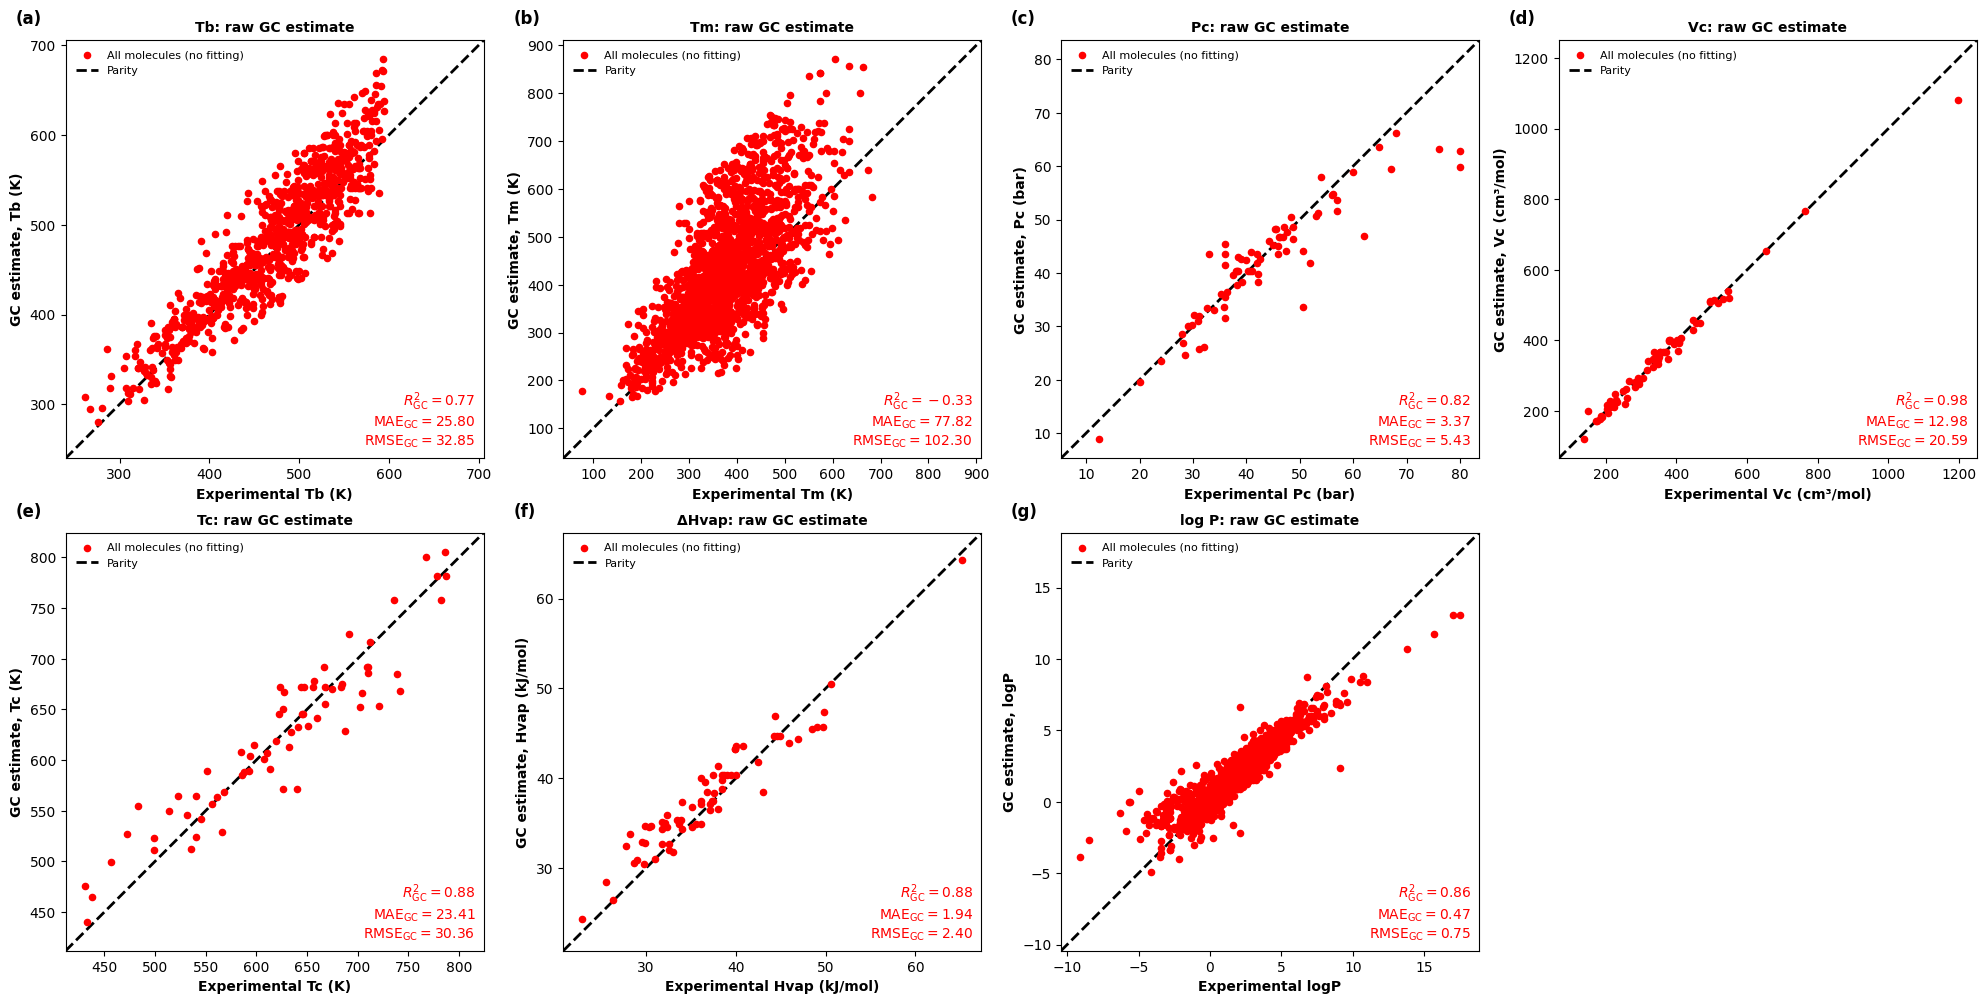

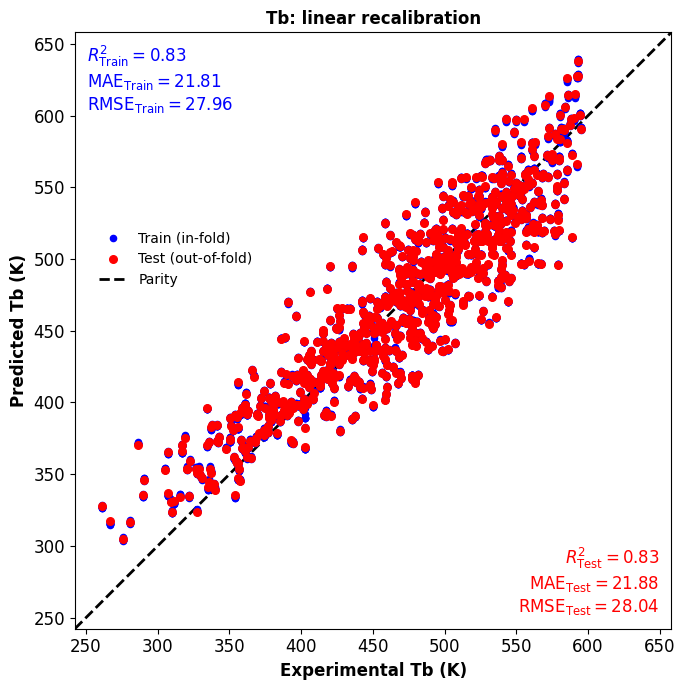

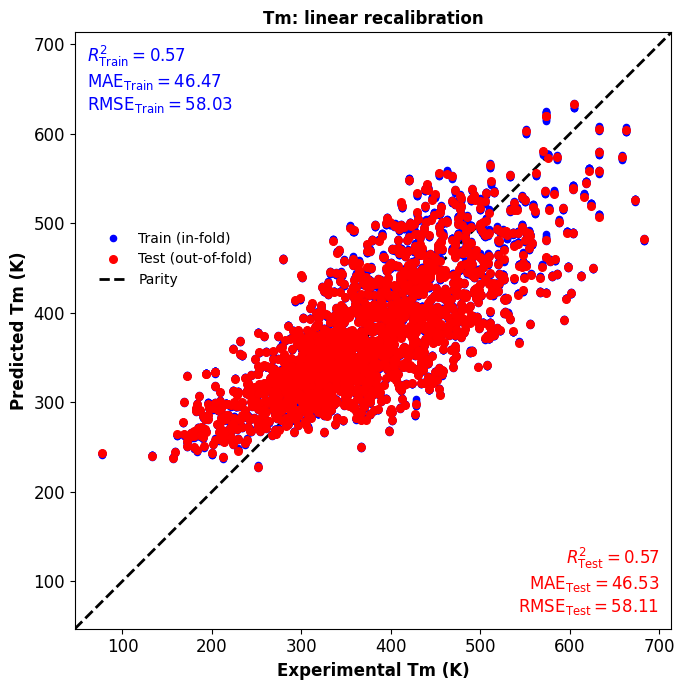

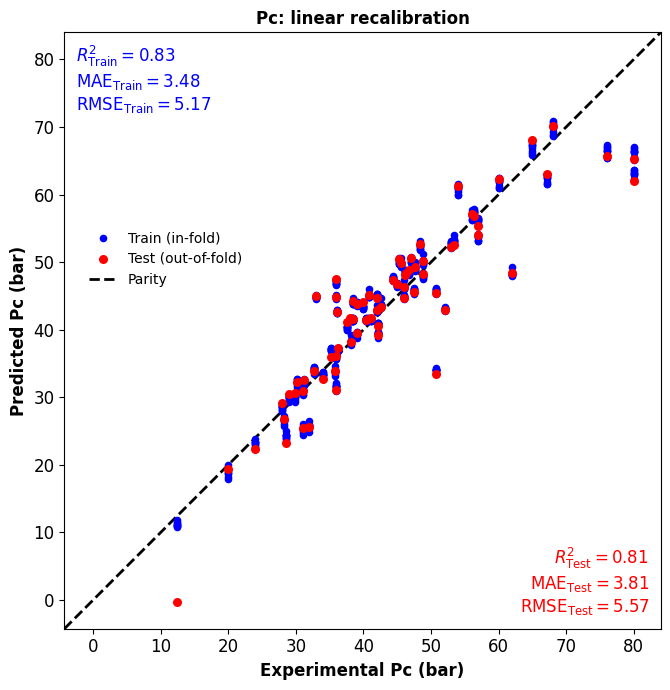

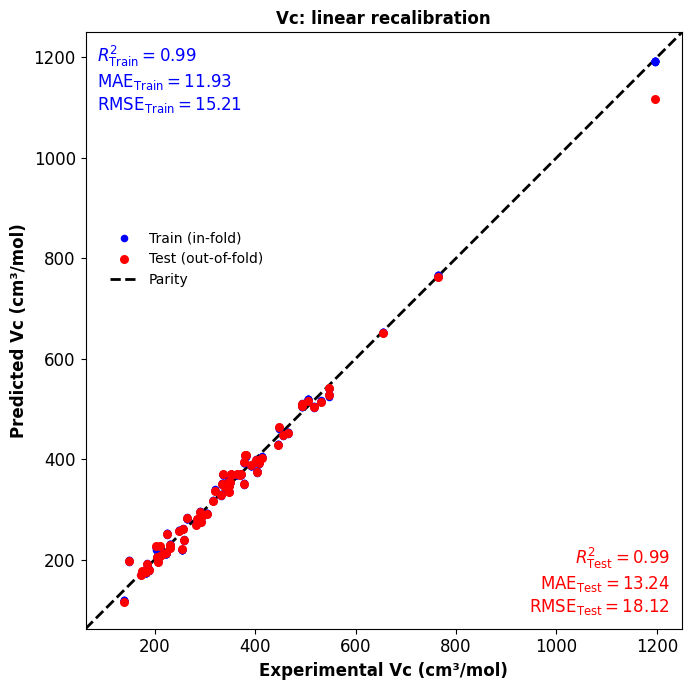

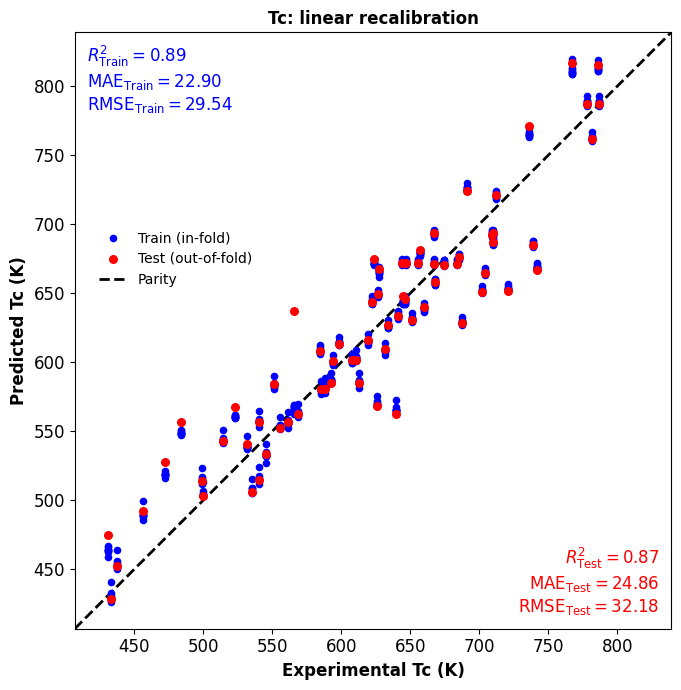

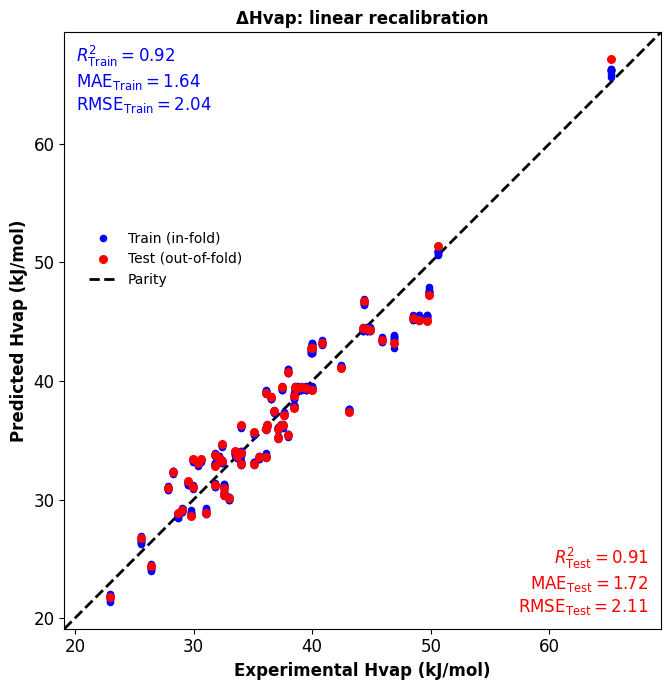

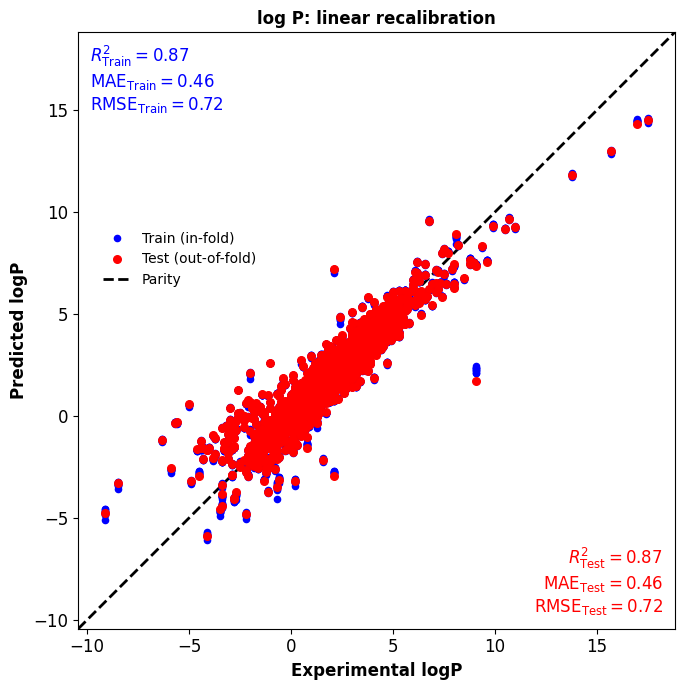

In [5]:
def plotRawGcParity(ax, code, predictions, fontsize=12):
    info = PROPERTIES[code]
    yTrue, yPred = predictions[info["xLabel"]].to_numpy(), predictions[info["yLabel"]].to_numpy()
    allValues = np.concatenate([yTrue, yPred])
    low, high = allValues.min(), allValues.max()
    margin = 0.05 * (high - low)
    low, high = low - margin, high + margin
    ax.scatter(yTrue, yPred, s=20, color=TEST_COLOR, zorder=2, label="All molecules (no fitting)")
    ax.plot([low, high], [low, high], "k--", linewidth=2, zorder=1, label="Parity")
    addMetricsText(ax, calculateMetrics(yTrue, yPred), "GC", TEST_COLOR, "lower right", fontsize)
    ax.set_xlabel(info["xLabel"], fontsize=fontsize, fontweight="bold")
    ax.set_ylabel(info["yLabel"].replace("Predicted", "GC estimate,"), fontsize=fontsize, fontweight="bold")
    ax.set_title(f"{info['label']}: raw GC estimate", fontsize=fontsize, fontweight="bold")
    ax.tick_params(axis="both", labelsize=fontsize)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper left", fontsize=fontsize - 2, frameon=False)


for code in PROPERTY_ORDER:
    runName = RUN_NAMES[code]
    fig, ax = plt.subplots(figsize=(8, 7))
    plotRawGcParity(ax, code, rawResults[code]["predictions"])
    fig.tight_layout()
    savePlot(fig, matchedDir / runName / f"{runName}_rawGC_parity.png")
    finishFigure(fig, show=False)

nCols = 4
nRows = int(np.ceil(len(PROPERTY_ORDER) / nCols))
fig, axes = plt.subplots(nRows, nCols, figsize=(5 * nCols, 5 * nRows))
for panel, (ax, code) in enumerate(zip(axes.ravel(), PROPERTY_ORDER)):
    plotRawGcParity(ax, code, rawResults[code]["predictions"], fontsize=10)
    ax.text(-0.12, 1.04, f"({chr(ord('a') + panel)})", transform=ax.transAxes, fontsize=12, fontweight="bold")
for ax in axes.ravel()[len(PROPERTY_ORDER):]:
    ax.axis("off")
fig.tight_layout()
savePlot(fig, matchedDir / "fig2_rawGC_parity_grid.png")
finishFigure(fig, show=showPlots)

for code in PROPERTY_ORDER:
    info, runName, lin = PROPERTIES[code], RUN_NAMES[code], linearResults[code]
    trainPart = lin["predictions"][lin["predictions"]["Set"] == "Train"]
    testPart = lin["predictions"][lin["predictions"]["Set"] == "Test"]
    plotParity(trainPart[info["xLabel"]], trainPart[info["yLabel"]], testPart[info["xLabel"]],
               testPart[info["yLabel"]], info["xLabel"], info["yLabel"],
               f"{info['label']}: linear recalibration", lin["trainOverall"], lin["testOverall"],
               savePath=matchedDir / runName / f"{runName}_linear_CV_parity.png",
               trainLabel="Train (in-fold)", testLabel="Test (out-of-fold)", show=showPlots)

## 6. Consistency checks

The notebook stops with an error if a check fails.

1. The fold sizes add up to the number of molecules, and every molecule is held out
   exactly once.
2. When the predictions of notebook 04 are present: for every property, the GC-GP test
   rows have the same row indices, SMILES, experimental values and fold labels as the
   baselines, so all three models are scored on identical molecules in identical folds.
3. In a full run: the raw GC metrics reproduce the values reported in the V3/V4
   manuscript (Table 2), which were computed from the same curated files.

In [6]:
# Raw GC metrics (MAE, RMSE, R²) of Table 2 in the V3/V4 manuscript, for a full run.
REFERENCE_RAW_GC = {
    "Tb": (25.799, 32.853, 0.768), "Tm": (77.821, 102.302, -0.329), "Pc": (3.369, 5.427, 0.817),
    "Vc": (12.978, 20.586, 0.983), "Tc": (23.407, 30.359, 0.881), "Hvap": (1.938, 2.400, 0.883),
    "logP": (0.467, 0.750, 0.855),
}


def gcgpTestRows(code):
    path = gcgpDir / RUN_NAMES[code] / f"{RUN_NAMES[code]}_all_cv_predictions.csv"
    if not path.is_file():
        return None
    df = pd.read_csv(path, float_precision="round_trip")
    test = df[df["Set"] == "Test"].sort_values("RowIndex").reset_index(drop=True)
    if isFastRun() and (len(test) != len(propertyData[code]) or test["Fold"].nunique() != N_FOLDS):
        # A fast run uses fewer molecules and folds, so it cannot be matched with a full run of notebook 04.
        return None
    return test


checkRows = []
for code in PROPERTY_ORDER:
    info, data = PROPERTIES[code], propertyData[code]
    raw = rawResults[code]["predictions"].sort_values("RowIndex").reset_index(drop=True)
    linTest = linearResults[code]["predictions"].query("Set == 'Test'").sort_values("RowIndex").reset_index(drop=True)
    assert np.array_equal(raw["RowIndex"].to_numpy(), np.arange(len(data))), f"{code}: raw GC rows"
    assert np.array_equal(linTest["RowIndex"].to_numpy(), np.arange(len(data))), f"{code}: linear test rows"
    assert np.array_equal(raw["Fold"].to_numpy(), linTest["Fold"].to_numpy()), f"{code}: fold labels"

    gcgp = gcgpTestRows(code)
    gcgpStatus = "notebook 04 output not found"
    if gcgp is not None:
        assert len(gcgp) == len(data), f"{code}: GC-GP has {len(gcgp)} test rows, curated data {len(data)}"
        assert np.array_equal(gcgp["RowIndex"].to_numpy(), np.arange(len(data))), f"{code}: GC-GP row indices"
        assert (gcgp["SMILES"].to_numpy() == data["PubChem SMILES"].to_numpy()).all(), f"{code}: SMILES"
        assert np.allclose(gcgp.iloc[:, 0].to_numpy(), data[info["targetCol"]].to_numpy()), f"{code}: experimental values"
        assert np.array_equal(gcgp["Fold"].to_numpy(), raw["Fold"].to_numpy()), f"{code}: folds differ from notebook 04"
        gcgpStatus = "same molecules, values and folds"

    referenceStatus = "skipped (fast run)"
    if not isFastRun():
        s = rawResults[code]["summary"]
        got = (s["Overall_Test_MAE"], s["Overall_Test_RMSE"], s["Overall_Test_R2"])
        assert np.allclose(got, REFERENCE_RAW_GC[code], rtol=1e-3, atol=1e-3), \
            f"{code}: raw GC metrics {np.round(got, 3)} differ from the manuscript values {REFERENCE_RAW_GC[code]}"
        referenceStatus = "matches manuscript Table 2"
    checkRows.append({"Property": code, "Molecules": len(data), "Notebook 04": gcgpStatus,
                      "Raw GC vs manuscript": referenceStatus})

pd.DataFrame(checkRows)

,Property,Molecules,Notebook 04,Raw GC vs manuscript
0,Tb,886,"same molecules, values and folds",matches manuscript Table 2
1,Tm,1839,"same molecules, values and folds",matches manuscript Table 2
2,Pc,75,"same molecules, values and folds",matches manuscript Table 2
3,Vc,69,"same molecules, values and folds",matches manuscript Table 2
4,Tc,70,"same molecules, values and folds",matches manuscript Table 2
5,Hvap,70,"same molecules, values and folds",matches manuscript Table 2
6,logP,2978,"same molecules, values and folds",matches manuscript Table 2


## 7. Table 2: raw GC estimate, linear recalibration and GC-GP on the same molecules

All three models are scored on the out-of-fold predictions of the same molecules in
the same ten folds. GC-GP values are recomputed from the notebook 04 prediction files
with `calculateMetrics` and checked against `final_cv_summary.csv`.

* **ΔRMSE** is the relative change of GC-GP against the raw GC estimate and against the
  linear recalibration.
* The **bracket** is a bootstrap 95% interval of the absolute RMSE difference (GC-GP
  minus the other model; 2000 resamples of molecules, seed 0). An interval that excludes
  zero means the difference is unlikely to be a sampling effect.
* **p** is a Wilcoxon signed-rank test on the paired absolute errors.
* **Sig.** is "yes" only when both tests agree: the bootstrap interval excludes zero and
  p < 0.05. Very small differences can have a bootstrap interval that excludes zero
  (for example when GC-GP and the linear recalibration give almost identical
  predictions), so the interval alone is not used.
* **Coverage** is the share of molecules inside the nominal 95% interval, with a Wilson
  95% confidence interval. The raw GC estimate has no interval.

In [7]:
def wilsonInterval(successes, n, z=1.96):
    p = successes / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    halfWidth = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (centre - halfWidth), 100 * (centre + halfWidth)


def pairedComparison(yTrue, predA, predB, nResamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED):
    # RMSE(A) - RMSE(B): relative change, bootstrap interval and Wilcoxon p value.
    errA, errB = yTrue - predA, yTrue - predB
    rmseA, rmseB = np.sqrt(np.mean(errA ** 2)), np.sqrt(np.mean(errB ** 2))
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(nResamples):
        i = rng.integers(0, len(yTrue), len(yTrue))
        diffs.append(np.sqrt(np.mean(errA[i] ** 2)) - np.sqrt(np.mean(errB[i] ** 2)))
    low, high = np.percentile(diffs, [2.5, 97.5])
    pValue = stats.wilcoxon(np.abs(errA), np.abs(errB)).pvalue
    return 100 * (rmseA - rmseB) / rmseB, low, high, pValue


gcgpFiles = {code: gcgpTestRows(code) for code in PROPERTY_ORDER}
table2Df = None
if any(df is None for df in gcgpFiles.values()):
    missing = [RUN_NAMES[c] for c, df in gcgpFiles.items() if df is None]
    print("Table 2 skipped: notebook 04 predictions not found for " + ", ".join(missing)
          + ". Run notebooks/04_Final_GCGP_CrossValidation.ipynb, then this notebook again.")
else:
    finalSummaryPath = gcgpDir / "final_cv_summary.csv"
    finalSummary = pd.read_csv(finalSummaryPath).set_index("Property") if finalSummaryPath.is_file() else None
    rows = []
    for code in PROPERTY_ORDER:
        info = PROPERTIES[code]
        yTrue = propertyData[code][info["targetCol"]].to_numpy(dtype=float)
        gc = propertyData[code][info["featureCols"][1]].to_numpy(dtype=float)
        lin = linearResults[code]["predictions"].query("Set == 'Test'").sort_values("RowIndex")
        gcgp = gcgpFiles[code]
        linPred, linCi = lin[info["yLabel"]].to_numpy(), lin["95% CI"].to_numpy()
        gpPred, gpCi = gcgp.iloc[:, 1].to_numpy(), gcgp["95% CI"].to_numpy()
        gcStats, linStats, gpStats = (calculateMetrics(yTrue, p) for p in (gc, linPred, gpPred))
        if finalSummary is not None and RUN_NAMES[code] in finalSummary.index:
            assert np.isclose(gpStats["RMSE"], finalSummary.loc[RUN_NAMES[code], "Overall_Test_RMSE"]), \
                f"{code}: GC-GP RMSE differs from final_cv_summary.csv"
        vsGc = pairedComparison(yTrue, gpPred, gc)
        vsLin = pairedComparison(yTrue, gpPred, linPred)
        gpInside = int(np.sum(np.abs(yTrue - gpPred) <= gpCi))
        linInside = int(np.sum(np.abs(yTrue - linPred) <= linCi))
        gpLow, gpHigh = wilsonInterval(gpInside, len(yTrue))
        linLow, linHigh = wilsonInterval(linInside, len(yTrue))
        row = {"Property": code, "Unit": info["unit"], "N": len(yTrue)}
        for prefix, s in [("GC", gcStats), ("Linear", linStats), ("GCGP", gpStats)]:
            row.update({f"{prefix}_R2": s["R2"], f"{prefix}_MAE": s["MAE"], f"{prefix}_RMSE": s["RMSE"],
                        f"{prefix}_MPE": s["MPE"]})
        row.update({"dRMSE_vs_GC_pct": vsGc[0], "dRMSE_vs_GC_low": vsGc[1], "dRMSE_vs_GC_high": vsGc[2],
                    "p_vs_GC": vsGc[3],
                    "dRMSE_vs_Linear_pct": vsLin[0], "dRMSE_vs_Linear_low": vsLin[1],
                    "dRMSE_vs_Linear_high": vsLin[2], "p_vs_Linear": vsLin[3],
                    "Linear_Coverage_pct": 100 * linInside / len(yTrue), "Linear_Coverage_low": linLow,
                    "Linear_Coverage_high": linHigh,
                    "GCGP_Coverage_pct": 100 * gpInside / len(yTrue), "GCGP_Coverage_low": gpLow,
                    "GCGP_Coverage_high": gpHigh})
        rows.append(row)
    table2Df = pd.DataFrame(rows)
    # A difference counts as significant only when both tests agree: the bootstrap
    # interval excludes zero and the Wilcoxon p value is below 0.05.
    for other in ["GC", "Linear"]:
        excludesZero = (table2Df[f"dRMSE_vs_{other}_high"] < 0) | (table2Df[f"dRMSE_vs_{other}_low"] > 0)
        table2Df[f"Significant_vs_{other}"] = excludesZero & (table2Df[f"p_vs_{other}"] < 0.05)
    table2Df.to_csv(matchedDir / "table2_matched_comparison.csv", index=False)


def formatTable2(df):
    def pValue(p):
        return "<0.001" if p < 0.001 else f"{p:.3f}"

    out = []
    for _, r in df.iterrows():
        unit = f" ({r['Unit']})" if isinstance(r["Unit"], str) and r["Unit"] else ""
        d = 3 if r["Property"] == "logP" else 2
        out.append({
            "Property": r["Property"] + unit, "N": r["N"],
            "GC R²": f"{r['GC_R2']:.2f}", "GC MAE": f"{r['GC_MAE']:.{d}f}", "GC RMSE": f"{r['GC_RMSE']:.{d}f}",
            "Linear R²": f"{r['Linear_R2']:.2f}", "Linear MAE": f"{r['Linear_MAE']:.{d}f}",
            "Linear RMSE": f"{r['Linear_RMSE']:.{d}f}",
            "GCGP R²": f"{r['GCGP_R2']:.2f}", "GCGP MAE": f"{r['GCGP_MAE']:.{d}f}", "GCGP RMSE": f"{r['GCGP_RMSE']:.{d}f}",
            "ΔRMSE vs GC [95% CI]": f"{r['dRMSE_vs_GC_pct']:+.1f} % [{r['dRMSE_vs_GC_low']:+.{d}f}, {r['dRMSE_vs_GC_high']:+.{d}f}]",
            "p vs GC": pValue(r["p_vs_GC"]),
            "Sig. vs GC": "yes" if r["Significant_vs_GC"] else "no",
            "ΔRMSE vs linear [95% CI]": f"{r['dRMSE_vs_Linear_pct']:+.2f} % [{r['dRMSE_vs_Linear_low']:+.{d+1}f}, {r['dRMSE_vs_Linear_high']:+.{d+1}f}]",
            "p vs linear": pValue(r["p_vs_Linear"]),
            "Sig. vs linear": "yes" if r["Significant_vs_Linear"] else "no",
            "Linear coverage (%)": f"{r['Linear_Coverage_pct']:.1f} ({r['Linear_Coverage_low']:.1f}–{r['Linear_Coverage_high']:.1f})",
            "GCGP coverage (%)": f"{r['GCGP_Coverage_pct']:.1f} ({r['GCGP_Coverage_low']:.1f}–{r['GCGP_Coverage_high']:.1f})",
        })
    return pd.DataFrame(out)


if table2Df is not None:
    table2Formatted = formatTable2(table2Df)
    table2Formatted.to_csv(matchedDir / "table2_matched_comparison_formatted.csv", index=False)
    display(table2Formatted)

,Property,N,GC R²,GC MAE,GC RMSE,Linear R²,Linear MAE,Linear RMSE,GCGP R²,GCGP MAE,GCGP RMSE,ΔRMSE vs GC [95% CI],p vs GC,Sig. vs GC,ΔRMSE vs linear [95% CI],p vs linear,Sig. vs linear,Linear coverage (%),GCGP coverage (%)
0,Tb (K),886,0.77,25.80,32.85,0.83,21.88,28.04,0.85,20.78,26.57,"-19.1 % [-7.55, -5.13]",<0.001,yes,"-5.27 % [-1.968, -1.010]",0.001,yes,93.7 (91.9–95.1),93.8 (92.0–95.2)
1,Tm (K),1839,-0.33,77.82,102.30,0.57,46.53,58.11,0.62,43.59,55.00,"-46.2 % [-51.22, -43.21]",<0.001,yes,"-5.36 % [-3.990, -2.264]",<0.001,yes,94.8 (93.7–95.7),94.7 (93.5–95.6)
2,Pc (bar),75,0.82,3.37,5.43,0.81,3.81,5.57,0.81,3.59,5.55,"+2.3 % [-0.17, +0.49]",0.461,no,"-0.33 % [-0.623, +0.480]",0.223,no,92.0 (83.6–96.3),89.3 (80.3–94.5)
3,Vc (cm³/mol),69,0.98,12.98,20.59,0.99,13.24,18.12,0.99,13.23,18.12,"-12.0 % [-6.55, +1.07]",0.052,no,"-0.04 % [-0.016, -0.000]",0.123,no,94.2 (86.0–97.7),92.8 (84.1–96.9)
4,Tc (K),70,0.88,23.41,30.36,0.87,24.86,32.18,0.87,24.86,32.18,"+6.0 % [+0.21, +3.82]",0.046,yes,"-0.00 % [-0.001, +0.000]",0.923,no,94.3 (86.2–97.8),90.0 (80.8–95.1)
5,Hvap (kJ/mol),70,0.88,1.94,2.40,0.91,1.72,2.11,0.92,1.58,1.96,"-18.3 % [-0.75, -0.14]",0.028,yes,"-7.04 % [-0.421, +0.131]",0.404,no,97.1 (90.2–99.2),92.9 (84.3–96.9)
6,logP,2978,0.86,0.467,0.750,0.87,0.461,0.723,0.88,0.422,0.675,"-10.0 % [-0.111, -0.040]",<0.001,yes,"-6.67 % [-0.0769, -0.0186]",<0.001,yes,95.0 (94.1–95.7),94.2 (93.3–95.0)


## 8. Summary of the results

Written from the tables of this run and saved as
`Output_Data/jrgc_baseline/matched_cv/results_summary.md`.

In [8]:
def describeMatchedComparison(summaryDf, table2):
    lines = ["## Matched baselines: results", ""]
    if isFastRun():
        lines += ["> These numbers come from a FAST run (small subsets, fewer folds). Rerun without "
                  "GCGP_FAST_RUN before using them.", ""]
    lines.append(f"All models are scored on the curated molecules of each property in the same "
                 f"{N_FOLDS} folds as notebook 04.")
    lines.append("")
    for code in PROPERTY_ORDER:
        run = RUN_NAMES[code]
        unit = PROPERTIES[code]["unit"]
        unitText = f" {unit}" if unit else ""
        raw = summaryDf.query("Property == @run and Model == 'Raw GC estimate'").iloc[0]
        lin = summaryDf.query("Property == @run and Model == 'Linear recalibration'").iloc[0]
        d = 3 if code == "logP" else 2
        text = (f"- **{PROPERTIES[code]['label']}** ({int(raw['N_Molecules'])} molecules): raw GC estimate "
                f"R² = {raw['Overall_Test_R2']:.3f}, RMSE = {raw['Overall_Test_RMSE']:.{d}f}{unitText}; "
                f"linear recalibration (out-of-fold) R² = {lin['Overall_Test_R2']:.3f}, "
                f"RMSE = {lin['Overall_Test_RMSE']:.{d}f}{unitText}")
        if table2 is not None:
            r = table2.set_index("Property").loc[code]
            linSig = "significant" if r["Significant_vs_Linear"] else "not significant"
            gcSig = "significant" if r["Significant_vs_GC"] else "not significant"
            text += (f"; GC-GP R² = {r['GCGP_R2']:.3f}, RMSE = {r['GCGP_RMSE']:.{d}f}{unitText}. GC-GP changes "
                     f"RMSE by {r['dRMSE_vs_GC_pct']:+.1f} % against the raw GC estimate ({gcSig}) and by "
                     f"{r['dRMSE_vs_Linear_pct']:+.2f} % against the linear recalibration ({linSig})")
        lines.append(text + ".")
    if table2 is not None:
        t2 = table2.set_index("Property")
        better = lambda other: [c for c, r in t2.iterrows() if r[f"Significant_vs_{other}"] and r[f"dRMSE_vs_{other}_pct"] < 0]
        worse = lambda other: [c for c, r in t2.iterrows() if r[f"Significant_vs_{other}"] and r[f"dRMSE_vs_{other}_pct"] > 0]
        lines += ["", f"GC-GP is significantly more accurate than the raw GC estimate for "
                  f"{', '.join(PROPERTIES[c]['label'] for c in better('GC')) or 'no property'} and significantly less accurate for "
                  f"{', '.join(PROPERTIES[c]['label'] for c in worse('GC')) or 'no property'}. Against the linear recalibration it is significantly "
                  f"more accurate for {', '.join(PROPERTIES[c]['label'] for c in better('Linear')) or 'no property'}; for the other properties the "
                  f"kernel adds no significant accuracy beyond the refitted line.",
                  "", "A difference is called significant when the bootstrap 95% interval of the RMSE difference "
                  "excludes zero and the Wilcoxon signed-rank p value is below 0.05."]
    else:
        lines += ["", "GC-GP comparison not included: run notebook 04, then this notebook again."]
    return "\n".join(lines)


showAndSave(describeMatchedComparison(baselineSummaryDf, table2Df), matchedDir / "results_summary.md");

## Matched baselines: results

All models are scored on the curated molecules of each property in the same 10 folds as notebook 04.

- **Tb** (886 molecules): raw GC estimate R² = 0.768, RMSE = 32.85 K; linear recalibration (out-of-fold) R² = 0.831, RMSE = 28.04 K; GC-GP R² = 0.848, RMSE = 26.57 K. GC-GP changes RMSE by -19.1 % against the raw GC estimate (significant) and by -5.27 % against the linear recalibration (significant).
- **Tm** (1839 molecules): raw GC estimate R² = -0.329, RMSE = 102.30 K; linear recalibration (out-of-fold) R² = 0.571, RMSE = 58.11 K; GC-GP R² = 0.616, RMSE = 55.00 K. GC-GP changes RMSE by -46.2 % against the raw GC estimate (significant) and by -5.36 % against the linear recalibration (significant).
- **Pc** (75 molecules): raw GC estimate R² = 0.817, RMSE = 5.43 bar; linear recalibration (out-of-fold) R² = 0.808, RMSE = 5.57 bar; GC-GP R² = 0.809, RMSE = 5.55 bar. GC-GP changes RMSE by +2.3 % against the raw GC estimate (not significant) and by -0.33 % against the linear recalibration (not significant).
- **Vc** (69 molecules): raw GC estimate R² = 0.983, RMSE = 20.59 cm³/mol; linear recalibration (out-of-fold) R² = 0.987, RMSE = 18.12 cm³/mol; GC-GP R² = 0.987, RMSE = 18.12 cm³/mol. GC-GP changes RMSE by -12.0 % against the raw GC estimate (not significant) and by -0.04 % against the linear recalibration (not significant).
- **Tc** (70 molecules): raw GC estimate R² = 0.881, RMSE = 30.36 K; linear recalibration (out-of-fold) R² = 0.866, RMSE = 32.18 K; GC-GP R² = 0.866, RMSE = 32.18 K. GC-GP changes RMSE by +6.0 % against the raw GC estimate (significant) and by -0.00 % against the linear recalibration (not significant).
- **ΔHvap** (70 molecules): raw GC estimate R² = 0.883, RMSE = 2.40 kJ/mol; linear recalibration (out-of-fold) R² = 0.910, RMSE = 2.11 kJ/mol; GC-GP R² = 0.922, RMSE = 1.96 kJ/mol. GC-GP changes RMSE by -18.3 % against the raw GC estimate (significant) and by -7.04 % against the linear recalibration (not significant).
- **log P** (2978 molecules): raw GC estimate R² = 0.855, RMSE = 0.750; linear recalibration (out-of-fold) R² = 0.866, RMSE = 0.723; GC-GP R² = 0.883, RMSE = 0.675. GC-GP changes RMSE by -10.0 % against the raw GC estimate (significant) and by -6.67 % against the linear recalibration (significant).

GC-GP is significantly more accurate than the raw GC estimate for Tb, Tm, ΔHvap, log P and significantly less accurate for Tc. Against the linear recalibration it is significantly more accurate for Tb, Tm, log P; for the other properties the kernel adds no significant accuracy beyond the refitted line.

A difference is called significant when the bootstrap 95% interval of the RMSE difference excludes zero and the Wilcoxon signed-rank p value is below 0.05.

## 9. Legacy baseline: fitted linear model on one 80/20 split (SI Table S4, Fig. S3)

This is the baseline of the earlier manuscript versions, unchanged. It uses the
uncurated input files restricted to molecules found in
`Input_Data/raw/feature_engineered_raw_data.csv`, one 80/20 split (seed 42), and for Tb
and Tm four topological indices (Wiener, Zagreb M1, Zagreb M2, Randić) as extra inputs.
Its molecules, split and inputs differ from notebook 04, so its numbers must not be
compared with the GC-GP results; use Table 2 above for that. It is kept for SI Table S4
and Fig. S3, and because notebooks 04 and 07 read its files
(`JRGC_statistical_metrics.csv`, `JRGC_train_*.csv`, `JRGC_test_*.csv`), whose names and
location are unchanged.

### 9.1 Data

In [9]:
descriptorTable = loadDescriptorTable()

overview = pd.DataFrame([
    {"Property": code,
     "Molecules": len(prepareBaselineData(code, descriptorTable)),
     "Baseline inputs": ", ".join(BASELINE_FEATURES[code])}
    for code in PROPERTY_ORDER
])
overview

,Property,Molecules,Baseline inputs
0,Tb,964,"Mol. wt., Wiener, Zagreb_M1, Zagreb_M2, Randic..."
1,Tm,1928,"Mol. wt., Wiener, Zagreb_M1, Zagreb_M2, Randic..."
2,Pc,73,"Mol. wt., JR Pc /Bars"
3,Vc,69,"Mol. wt., JR Vc /(cm3 mol-1)"
4,Tc,73,"Mol. wt., JR Tc /K"
5,Hvap,75,"Mol. Wt., JR Hvap /(kJ mol-1)"
6,logP,3463,"Mol. wt., Log P (JR)"


### 9.2 Fit the legacy baseline for each property

For every property: split 80/20, fit the linear model on the training set, and predict
both sets. Blue points are training molecules and red points are test molecules.

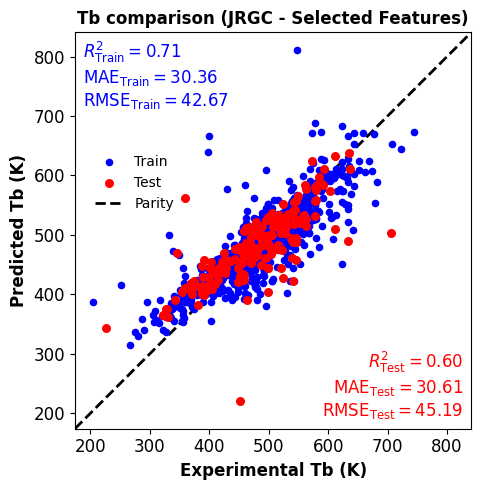

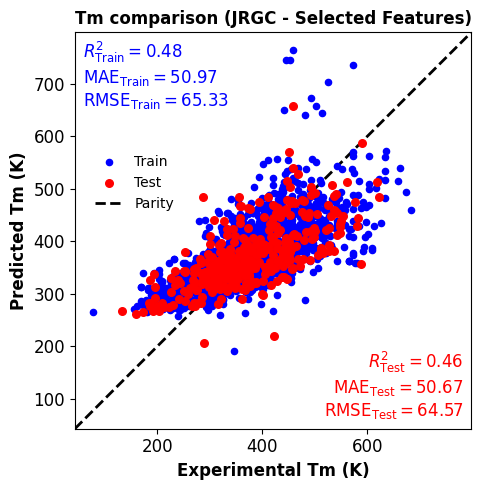

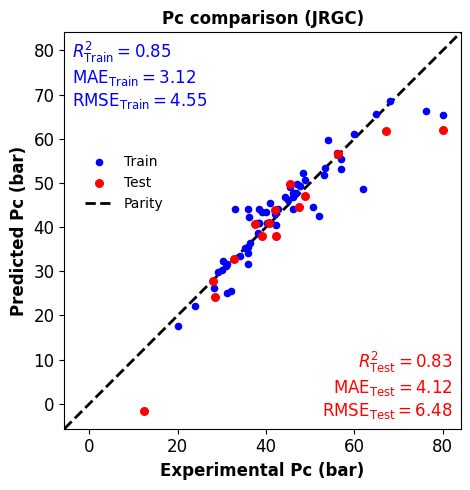

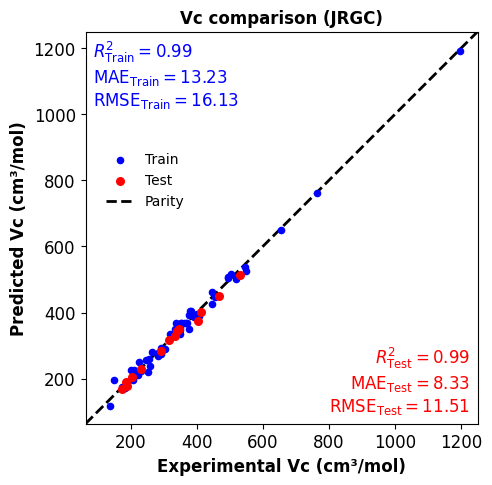

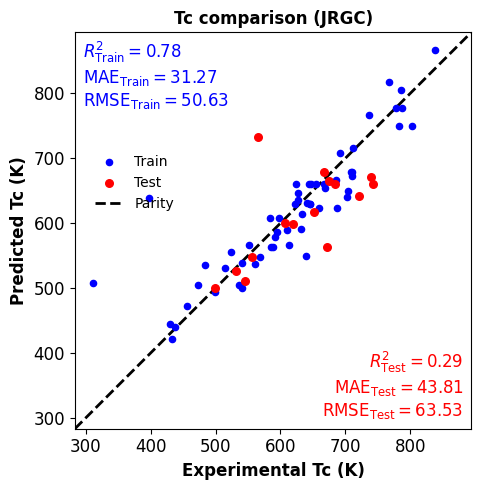

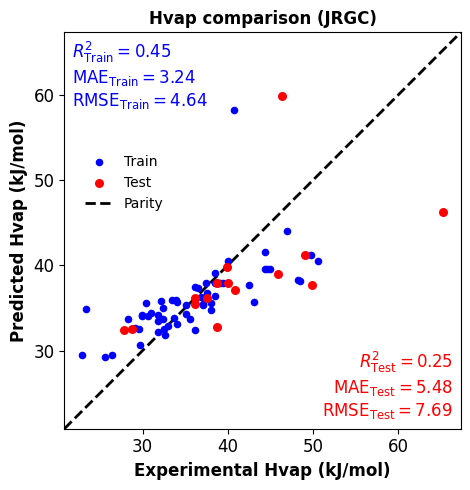

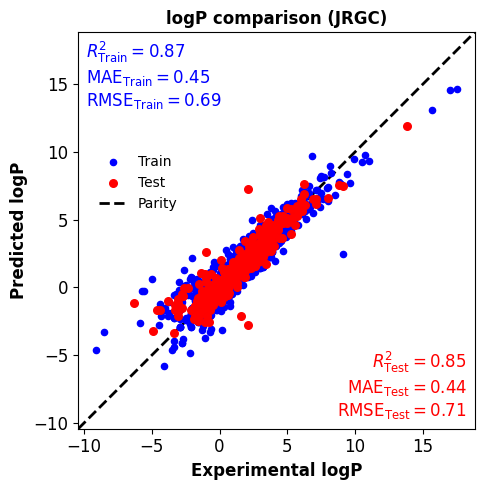

In [10]:
metricRows = []
coefficientTables = {}
for code in PROPERTY_ORDER:
    rows, coefficients = runBaseline(code, descriptorTable, outputDir)
    metricRows.extend(rows)
    coefficientTables[code] = coefficients

### 9.3 Error metrics

The first row for each property is the fitted legacy baseline; the second row is the raw
GC estimate on the same 80/20 test molecules.

In [11]:
metricsDf = pd.DataFrame(metricRows)
metricsDf.to_csv(outputDir / "JRGC_statistical_metrics.csv", index=False)

metricsDf[["Property", "Model", "N_Train", "N_Test", "R2_Train", "R2_Test",
           "MAE_Test", "RMSE_Test", "MAPE_Test"]]

,Property,Model,N_Train,N_Test,R2_Train,R2_Test,MAE_Test,RMSE_Test,MAPE_Test
0,Tb,Linear GC baseline (fitted),771,193,0.707,0.604,30.613,45.186,6.746
1,Tb,Raw GC prediction,771,193,0.335,0.546,32.904,48.358,6.916
2,Tm,Linear GC baseline (fitted),1542,386,0.477,0.462,50.667,64.567,14.465
3,Tm,Raw GC prediction,1542,386,-1.908,-1.067,89.668,126.549,24.066
4,Pc,Linear GC baseline (fitted),58,15,0.855,0.831,4.119,6.479,13.703
5,Pc,Raw GC prediction,58,15,0.844,0.855,3.659,5.990,8.289
6,Vc,Linear GC baseline (fitted),55,14,0.991,0.989,8.335,11.509,2.449
7,Vc,Raw GC prediction,55,14,0.982,0.990,7.000,10.979,1.932
8,Tc,Linear GC baseline (fitted),58,15,0.782,0.289,43.808,63.532,6.781
9,Tc,Raw GC prediction,58,15,0.758,0.729,28.223,39.236,4.246


### 9.4 Where the linear correction helps

A positive number means the fitted baseline has a lower test RMSE than the raw GC
estimate on this split.

In [ ]:
pivot = metricsDf.pivot(index="Property", columns="Model", values="RMSE_Test").loc[PROPERTY_ORDER]
pivot["RMSE reduction from fitting"] = pivot["Raw GC prediction"] - pivot["Linear GC baseline (fitted)"]
pivot.round(2)

### 9.5 Fitted coefficients for Tb and Tm

Coefficients refer to standardized inputs, so their sizes can be compared directly.

In [ ]:
pd.concat({code: coefficientTables[code] for code in ["Tb", "Tm"]}, names=["Property", None])

### 9.6 Summary of the legacy results

Saved as `Output_Data/jrgc_baseline/results_summary.md`, as before.

In [ ]:
from gcgp.narrative import describeBaseline

showAndSave(describeBaseline(metricsDf), outputDir / "results_summary.md");